In [98]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [99]:
df = pd.read_csv(r"data\final.csv")
df = df.drop(df[df["population"].isna()].index)
df = df.drop(df[df['name'].str.endswith('apskritis')].index)
df.head(50)

,name,year,month,infection,forest cover,population,area,oro_temp,juntamoji_temp,debesuotumas,slegis_juros_lyg,santyk_oro_dregme,kritutliu_kiekis
1,Alytaus m. sav.,2004,3,1,30.4,70053.0,39.0,1.406452,NaN,NaN,NaN,NaN,40.3
2,Druskininkų sav.,2004,3,0,69.2,24665.0,453.0,1.687097,NaN,NaN,NaN,NaN,41.4
3,Alytaus r. sav.,2004,3,0,24.6,31741.0,1403.0,1.406452,NaN,NaN,NaN,NaN,40.3
4,Lazdijų r. sav.,2004,3,0,34.8,26221.0,1306.0,1.687097,NaN,NaN,NaN,NaN,41.4
5,Varėnos r. sav.,2004,3,0,69.0,30071.0,2216.0,1.406452,NaN,NaN,NaN,NaN,40.3
7,Kauno m. sav.,2004,3,18,20.6,363952.0,157.0,1.593548,NaN,NaN,NaN,NaN,59.2
8,Jonavos r. sav.,2004,3,0,41.8,51510.0,944.0,1.677419,NaN,NaN,NaN,NaN,34.1
9,Kaišiadorių r. sav.,2004,3,2,31.4,37117.0,1087.0,1.593548,NaN,NaN,NaN,NaN,59.2
10,Kauno r. sav.,2004,3,1,32.6,83167.0,1496.0,1.593548,NaN,NaN,NaN,NaN,59.2
11,Kėdainių r. sav.,2004,3,0,25.5,63692.0,1677.0,1.490323,NaN,NaN,NaN,NaN,43.0


cases below 30 make up 64.0 % of cases and 98.0 % of datapoints


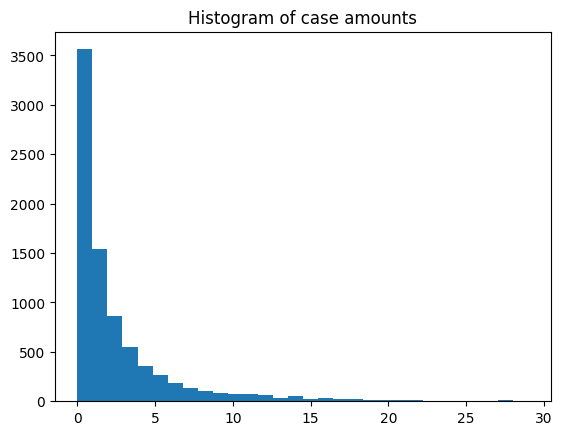

In [100]:
thresh = 30  
belowSeries = df[df['infection'] < thresh]['infection']
print(f"cases below {thresh} make up {round(100*sum(belowSeries)/sum(df['infection']),0)} % of cases and {round(100*len(belowSeries)/len(df['infection']),0)} % of datapoints")
plt.hist(belowSeries,bins=thresh)
plt.title("Histogram of case amounts")
plt.show()

In [101]:
import xgboost as xgb
model = xgb.XGBRegressor()
model.load_model("current_model.json")

X_test = df[(df["year"] >= 2017) & (df["name"] == 'Kauno apskritis')].drop(columns=["infection", "name"])
y_test = df[(df["year"] >= 2017) & (df["name"] == 'Kauno apskritis')]["infection"]
y_pred = model.predict(X_test)
y_pred = np.expm1(y_pred)

Kauno m. sav. MAE: 11.80281690140845
Vilniaus m. sav. MAE: 23.74418604651163


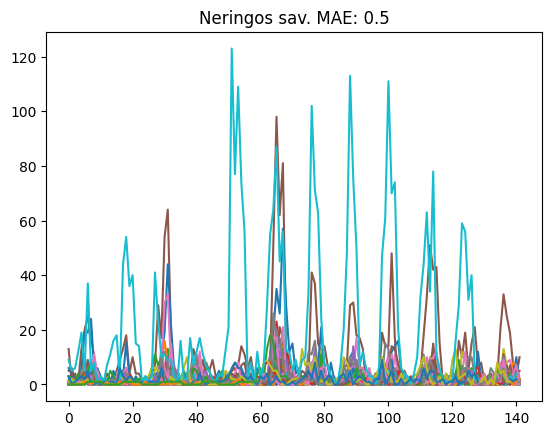

In [110]:
l = []
for location in df['name'].unique():
    X_test = df[(df["year"] < 2017) & (df["name"] == location)].drop(columns=["infection", "name"])
    y_test = df[(df["year"] < 2017) & (df["name"] == location)]["infection"]
    y_pred = model.predict(X_test)
    y_pred = list(round(y,0) for y in np.expm1(y_pred))
    if len(y_test) == 0:
        print(location)
        continue
    tempx = list(range(len(y_test)))
    mae = sum(abs(y_pred-y_test))/len(y_test)
    plt.title(f'{location} MAE: {mae}')
    if mae> 9: print(f'{location} MAE: {mae}')
    l.append(mae)
    #plt.plot(tempx,y_test, label="Real Cases")
    #plt.plot(tempx,y_pred, label="Predictions")
    plt.plot(tempx,abs(y_test-y_pred), label="Difference")
    #plt.legend()
    #plt.show()

In [108]:
X_test = df[(df["year"] >= 2017)].drop(columns=["infection", "name"])
y_test = df[(df["year"] >= 2017)]["infection"]
y_pred = model.predict(X_test)
y_pred = list(round(y,0) for y in np.expm1(y_pred))


sum predictions 2194.0
sum true vals 4405
percentage of cases 0.49807037457434733
Mean absolute error 2.6767578125


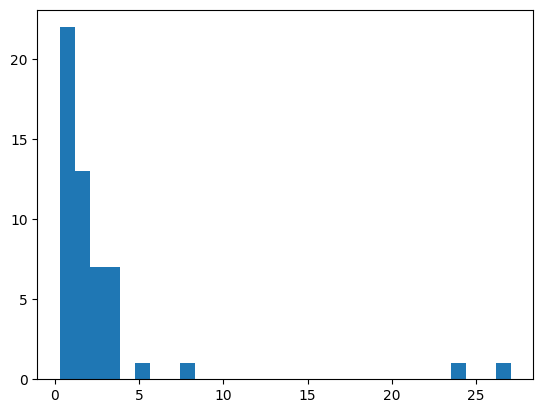

In [109]:
print("sum predictions", sum(y_pred)) 
print("sum true vals", sum(y_test))
print("percentage of cases", sum(y_pred)/sum(y_test))
print("Mean absolute error", sum(abs(y_pred-y_test))/len(y_test))
plt.hist(l,bins=30)
plt.show()